# 02 · Baseline — XGBoost on the raw data

Goal: a reference score that later experiments must beat. **Raw** means *no* cleaning, imputation or feature
engineering. The only changes are the ones XGBoost needs to accept the data: the opening date becomes an integer
(days since epoch) and text columns become pandas `category` (handled natively by XGBoost). NaNs are left as they are.

**Protocol (used in every notebook):**
* 20% stratified **holdout** (400 mules) is never used for training, tuning or calibration and only gives the final score.
* On the remaining 80%: **5-fold stratified CV**, giving out-of-fold (OOF) predictions for every dev row.
* **Weighted log-loss**: mules weighted by the class ratio #legit/#mule = 49 (the textbook "balanced" weight), the same
  weight in the early-stopping eval set, so the loss curves below show the real training objective. Early stopping on
  validation weighted log-loss. GPU (`device=cuda`).
* Metrics: **PR-AUC** (ranking quality under imbalance), ROC-AUC, and, because the case study scores
  *probability closeness*, **log-loss and Brier** (no-skill reference: 0.098 / 0.0196).

In [1]:
import sys; sys.path.insert(0, '..')
from time import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve, roc_curve, confusion_matrix, f1_score
from src.data import DataLoader, ID, TARGET
from src.model import XGBCV, evaluate

BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'axes.titleweight': 'bold', 'axes.titlesize': 11})
pd.set_option('display.float_format', '{:.4f}'.format)

train = DataLoader().load('train')

def to_raw(df):
    """Minimal encoding so XGBoost accepts the frame: date -> int days, text -> category."""
    X = df.drop(columns=[ID, TARGET], errors='ignore')
    X['account_opening_date'] = X.account_opening_date.astype('int64') // 86_400_000_000
    for c in X.select_dtypes(exclude='number').columns:
        X[c] = X[c].astype('category')
    return X

X, y = to_raw(train), train[TARGET]
X_dev, X_hold, y_dev, y_hold = train_test_split(X, y, test_size=.2, stratify=y, random_state=42)
print(f'dev {X_dev.shape} ({y_dev.sum()} mules) | holdout {X_hold.shape} ({y_hold.sum()} mules)')

dev (80000, 176) (1600 mules) | holdout (20000, 176) (400 mules)


## 1. Train — 5-fold weighted XGBoost on GPU

In [2]:
t = time()
base = XGBCV().fit(X_dev, y_dev)
print(f'trained in {time() - t:.0f}s | mule weight = {base.pos_weight_:.1f} | best iterations per fold: {base.best_iters_}')

trained in 9s | mule weight = 49.0 | best iterations per fold: [87, 94, 132, 107, 102]


## 2. Learning curves
Left: the training objective (weighted log-loss) on the train and validation part of each fold; the dot marks the
early-stopping iteration. Right: ROC-AUC per round (ROC-AUC is unaffected by class weights, unlike xgboost's
eval PR-AUC which would be computed on the re-weighted ~50/50 eval set and look artificially perfect).

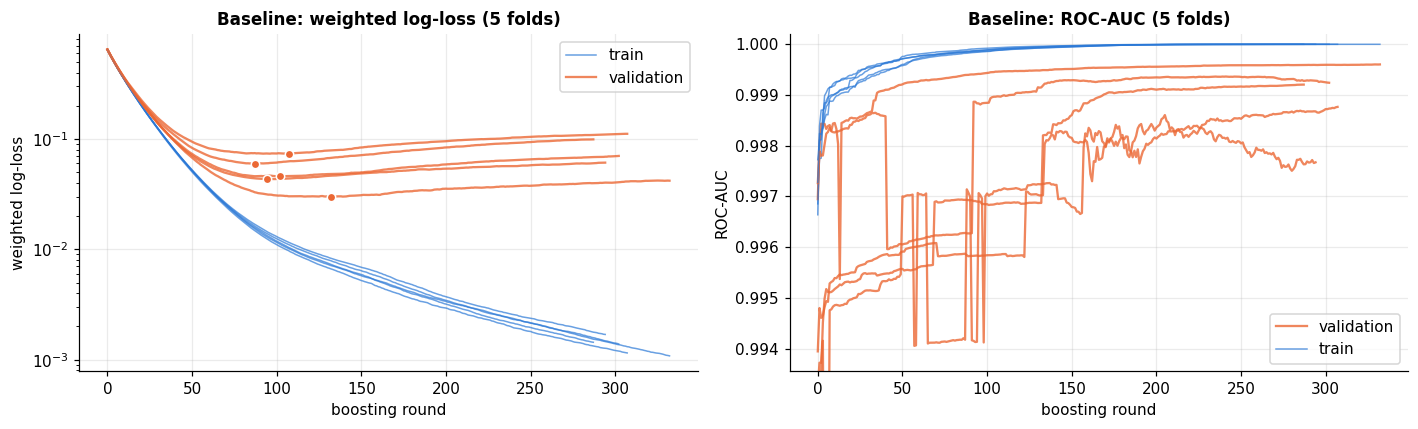

In [3]:
def plot_curves(cv, title):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
    for k, (c, m) in enumerate(zip(cv.curves_, cv.models_)):
        lab = (lambda s: s) if k == 0 else (lambda s: None)
        a1.plot(c['validation_0']['logloss'], color=BLUE, lw=1, alpha=.7, label=lab('train'))
        a1.plot(c['validation_1']['logloss'], color=ORANGE, lw=1.5, alpha=.8, label=lab('validation'))
        a1.scatter(m.best_iteration, c['validation_1']['logloss'][m.best_iteration], color=ORANGE, s=30, zorder=3, edgecolors='white')
        a2.plot(c['validation_1']['auc'], color=ORANGE, lw=1.5, alpha=.8, label=lab('validation'))
        a2.plot(c['validation_0']['auc'], color=BLUE, lw=1, alpha=.7, label=lab('train'))
    a1.set(title=f'{title}: weighted log-loss (5 folds)', xlabel='boosting round', ylabel='weighted log-loss', yscale='log')
    lo = min(min(c['validation_1']['auc'][10:]) for c in cv.curves_)
    a2.set(title=f'{title}: ROC-AUC (5 folds)', xlabel='boosting round', ylabel='ROC-AUC', ylim=(lo - .0005, 1.0002))
    a1.legend(); a2.legend(loc='lower right'); plt.tight_layout(); plt.show()

plot_curves(base, 'Baseline')

## 3. Scores out of the box
The model was trained with mules up-weighted ×49, so its raw scores are **inflated**: it behaves as if the mule
rate were ~50%, not 2%. Ranking metrics are unaffected; log-loss/Brier will look poor.

In [4]:
p_oof, p_hold = base.oof_, base.predict_proba(X_hold)
pd.DataFrame({'OOF (dev, 80k)': evaluate(y_dev, p_oof), 'holdout (20k)': evaluate(y_hold, p_hold)}).T

,roc_auc,pr_auc,log_loss,brier
"OOF (dev, 80k)",0.9978,0.9609,0.0203,0.0050
holdout (20k),0.9976,0.9602,0.0195,0.0048


## 4. Calibration: turning weighted scores back into probabilities
Three options, all fitted on the **OOF** predictions only and judged on the untouched holdout:
* **Prior correction** (closed form, no fitting): weighting multiplies the odds by *w*, so
  `p = s / (s + w·(1−s))`.
* **Platt scaling**: logistic regression on `logit(s)`.
* **Isotonic regression**: monotone step function (most flexible, can overfit with few positives).

In [5]:
logit = lambda p: np.log(np.clip(p, 1e-7, 1 - 1e-7) / (1 - np.clip(p, 1e-7, 1 - 1e-7)))
w = base.pos_weight_
platt = LogisticRegression(C=1e6).fit(logit(p_oof)[:, None], y_dev)
iso = IsotonicRegression(out_of_bounds='clip', y_min=1e-6, y_max=1 - 1e-6).fit(p_oof, y_dev)
calibrators = {
    'raw (weighted scale)': lambda s: s,
    'prior correction': lambda s: s / (s + w * (1 - s)),
    'Platt': lambda s: platt.predict_proba(logit(s)[:, None])[:, 1],
    'isotonic': lambda s: iso.predict(s),
}
cal = pd.DataFrame({name: evaluate(y_hold, f(p_hold)) for name, f in calibrators.items()}).T
cal['mean predicted p'] = [f(p_hold).mean() for f in calibrators.values()]
print(f'actual holdout mule rate = {y_hold.mean():.4f}')
cal

actual holdout mule rate = 0.0200


,roc_auc,pr_auc,log_loss,brier,mean predicted p
raw (weighted scale),0.9976,0.9602,0.0195,0.0048,0.0284
prior correction,0.9976,0.9602,0.0173,0.0044,0.0138
Platt,0.9976,0.9602,0.0120,0.0030,0.0189
isotonic,0.9953,0.9540,0.0119,0.0031,0.0189


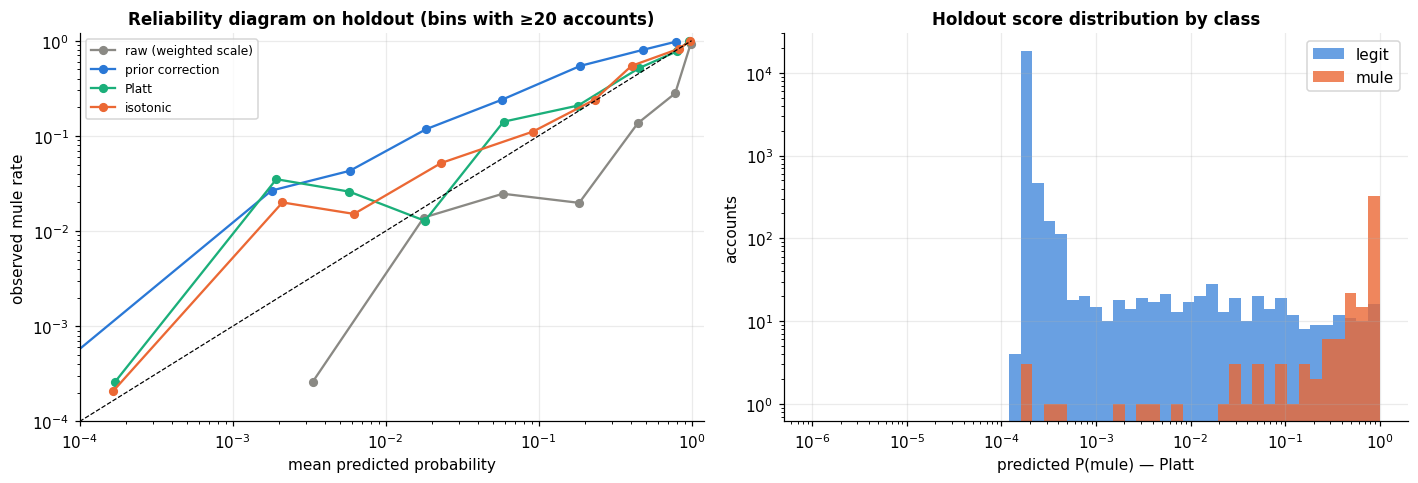

In [6]:
def reliability(y, p, edges=(0, 1e-3, 3e-3, .01, .03, .1, .3, .6, .9, 1)):
    """Observed rate vs mean prediction in fixed (log-spaced) bins; quantile bins collapse at a 2% base rate."""
    b = np.digitize(p, edges[1:-1])
    g = pd.DataFrame({'y': np.asarray(y), 'p': p, 'b': b}).groupby('b').agg(p=('p', 'mean'), y=('y', 'mean'), n=('y', 'size'))
    return g[g.n >= 20]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for (name, f), col in zip(calibrators.items(), [GRAY, BLUE, AQUA, ORANGE]):
    r = reliability(y_hold, f(p_hold))
    axes[0].plot(r.p, r.y, marker='o', ms=5, lw=1.5, color=col, label=name)
axes[0].plot([1e-4, 1], [1e-4, 1], ls='--', color='black', lw=.8)
axes[0].set(xscale='log', yscale='log', xlim=(1e-4, 1.2), ylim=(1e-4, 1.2), xlabel='mean predicted probability',
            ylabel='observed mule rate', title='Reliability diagram on holdout (bins with ≥20 accounts)')
axes[0].legend(fontsize=8)
best_cal = 'Platt'   # same log-loss as isotonic, but strictly monotone -> keeps the ranking (AUC) intact
p_cal = calibrators[best_cal](p_hold)
bins = np.logspace(-6, 0, 50)
axes[1].hist(p_cal[y_hold == 0], bins=bins, color=BLUE, alpha=.7, label='legit', density=False)
axes[1].hist(p_cal[y_hold == 1], bins=bins, color=ORANGE, alpha=.8, label='mule', density=False)
axes[1].set(xscale='log', yscale='log', xlabel=f'predicted P(mule) — {best_cal}', ylabel='accounts', title='Holdout score distribution by class')
axes[1].legend(); plt.tight_layout(); plt.show()

## 5. ROC / PR curves and an operating point
The threshold is chosen on the **OOF** predictions (max F1) and then applied to the holdout.

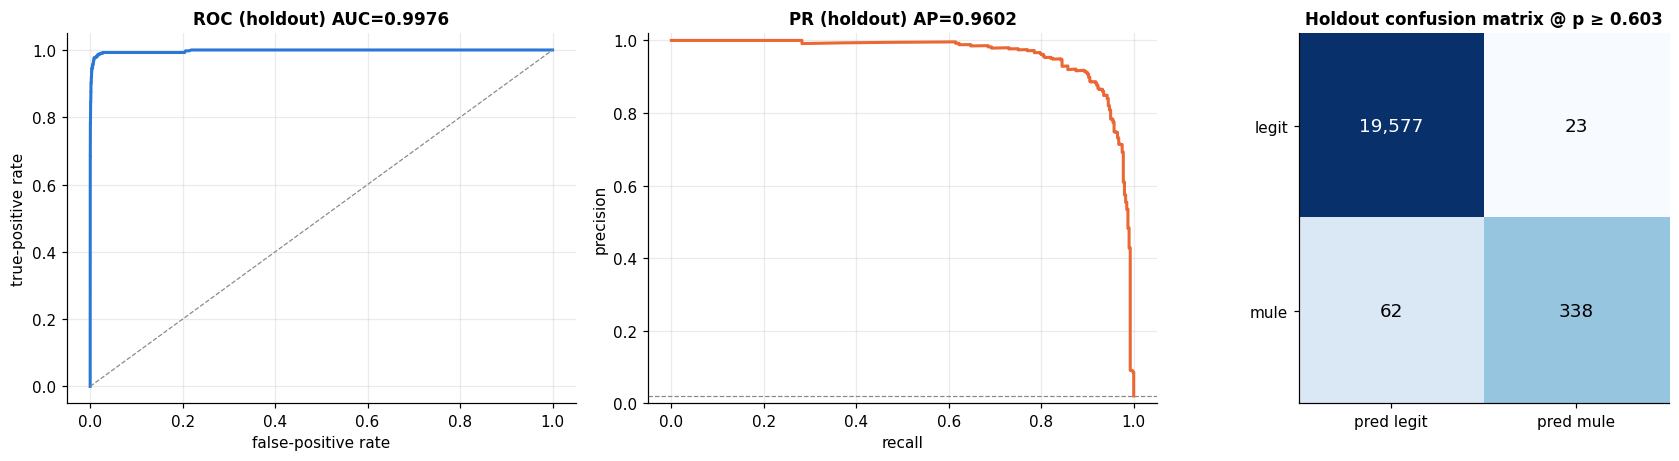

threshold 0.603: precision 0.936, recall 0.845, F1 0.888


In [7]:
f_best = calibrators[best_cal]
p_oof_cal = f_best(p_oof)
prec, rec, thr = precision_recall_curve(y_dev, p_oof_cal)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
t_star = thr[np.argmax(f1[:-1])]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
fpr, tpr, _ = roc_curve(y_hold, p_cal)
axes[0].plot(fpr, tpr, color=BLUE, lw=2); axes[0].plot([0, 1], [0, 1], ls='--', color=GRAY, lw=.8)
axes[0].set(xlabel='false-positive rate', ylabel='true-positive rate', title=f'ROC (holdout) AUC={cal.loc[best_cal, "roc_auc"]:.4f}')
pr, rc, _ = precision_recall_curve(y_hold, p_cal)
axes[1].plot(rc, pr, color=ORANGE, lw=2); axes[1].axhline(y_hold.mean(), ls='--', color=GRAY, lw=.8)
axes[1].set(xlabel='recall', ylabel='precision', title=f'PR (holdout) AP={cal.loc[best_cal, "pr_auc"]:.4f}', ylim=(0, 1.02))
cm = confusion_matrix(y_hold, p_cal >= t_star)
axes[2].imshow(cm, cmap='Blues', norm=plt.matplotlib.colors.LogNorm()); axes[2].grid(False)
for (i, j), v in np.ndenumerate(cm):
    axes[2].text(j, i, f'{v:,}', ha='center', va='center', fontsize=12, color='white' if v > 1000 else 'black')
axes[2].set(xticks=[0, 1], yticks=[0, 1], xticklabels=['pred legit', 'pred mule'], yticklabels=['legit', 'mule'],
            title=f'Holdout confusion matrix @ p ≥ {t_star:.3f}')
plt.tight_layout(); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f'threshold {t_star:.3f}: precision {tp / (tp + fp):.3f}, recall {tp / (tp + fn):.3f}, F1 {f1_score(y_hold, p_cal >= t_star):.3f}')

## 6. What does the baseline rely on?

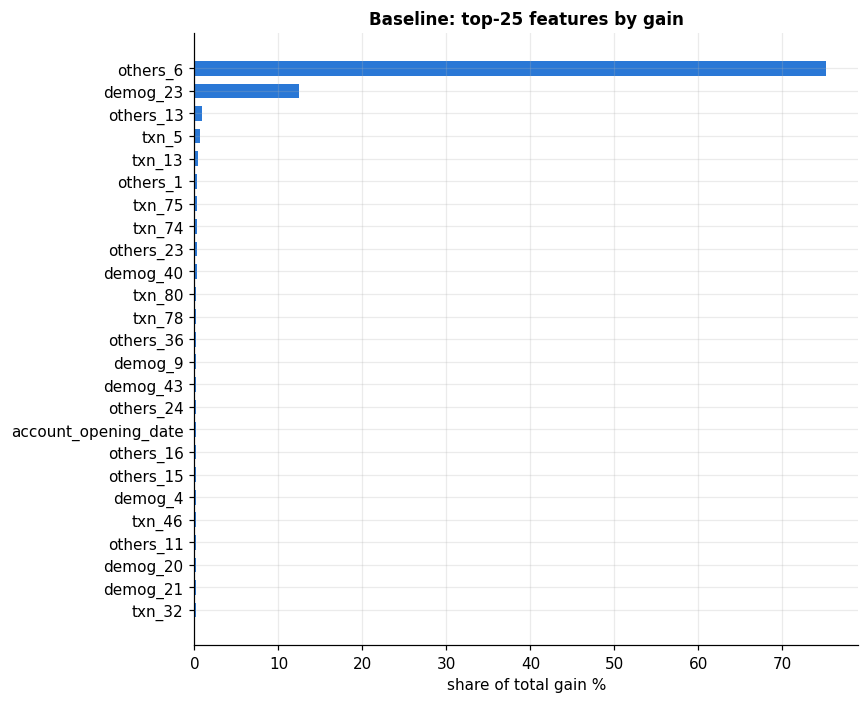

top-5 features hold 90% of total gain; 115 of 176 features used


In [8]:
imp = base.feature_importance('gain')
top = imp.head(25)[::-1]
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(top.index, top.values / imp.sum() * 100, color=BLUE, height=.65)
ax.set(xlabel='share of total gain %', title='Baseline: top-25 features by gain')
plt.tight_layout(); plt.show()
print(f'top-5 features hold {imp.head(5).sum() / imp.sum():.0%} of total gain; {(imp > 0).sum()} of {X.shape[1]} features used')

## 7. Too good to be true? Leakage check
PR-AUC 0.96 and ROC-AUC 0.998 from an untuned model on raw data is suspicious, and the importance plot shows why:
`others_6` and `demog_23` alone carry ~87% of the gain. EDA section 8 showed these are **day counters that stop when
the account is closed / frozen**: 100% of mules are frozen vs 3.2% of legit accounts, so the counters record the bank's
*reaction* to a mule rather than mule behaviour. A real monitoring system scores **open** accounts, where these
counters equal the account age for everyone and carry no signal. A model that relies on them would fail in production.

**Decision:** drop the 9 counter columns (`others_6/7/9/10/12/13/15/16`, `demog_23`) and re-run the *same* raw baseline.
That leak-free model is the real baseline every later experiment has to beat.

trained in 8s | best iterations per fold: [90, 138, 105, 102, 108]


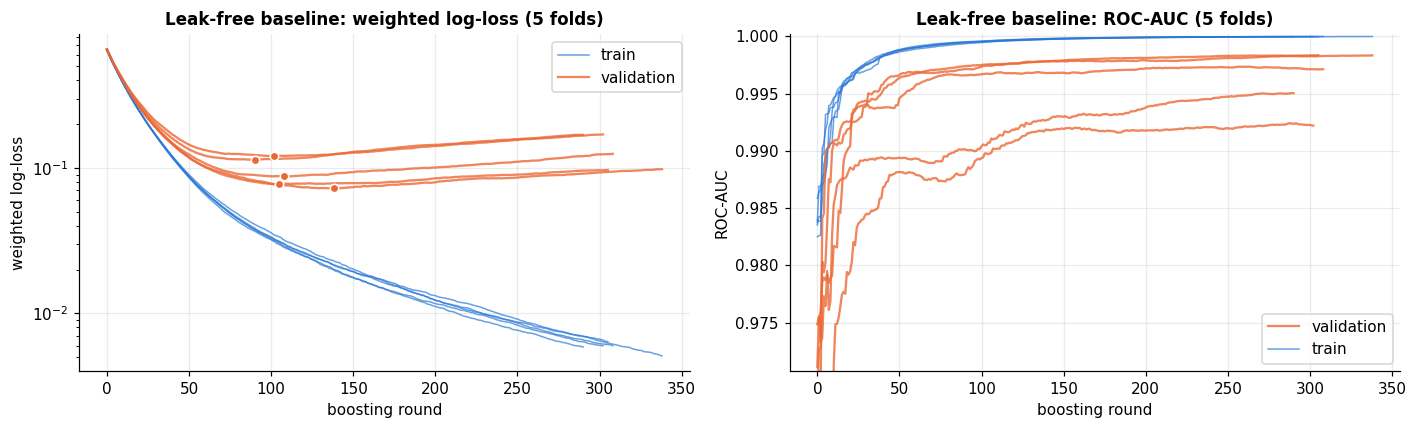

In [9]:
from src.features import COUNTERS
X_dev_nl, X_hold_nl = X_dev.drop(columns=COUNTERS), X_hold.drop(columns=COUNTERS)
t = time()
base_nl = XGBCV().fit(X_dev_nl, y_dev)
print(f'trained in {time() - t:.0f}s | best iterations per fold: {base_nl.best_iters_}')
plot_curves(base_nl, 'Leak-free baseline')

In [10]:
platt_nl = LogisticRegression(C=1e6).fit(logit(base_nl.oof_)[:, None], y_dev)
p_nl = platt_nl.predict_proba(logit(base_nl.predict_proba(X_hold_nl))[:, None])[:, 1]
p_nl_oof = platt_nl.predict_proba(logit(base_nl.oof_)[:, None])[:, 1]
pd.DataFrame({'raw baseline, all columns (leaky)': evaluate(y_hold, p_cal),
              'raw baseline, counters removed (leak-free)': evaluate(y_hold, p_nl)}).T

,roc_auc,pr_auc,log_loss,brier
"raw baseline, all columns (leaky)",0.9976,0.9602,0.0120,0.0030
"raw baseline, counters removed (leak-free)",0.9932,0.9288,0.0164,0.0038


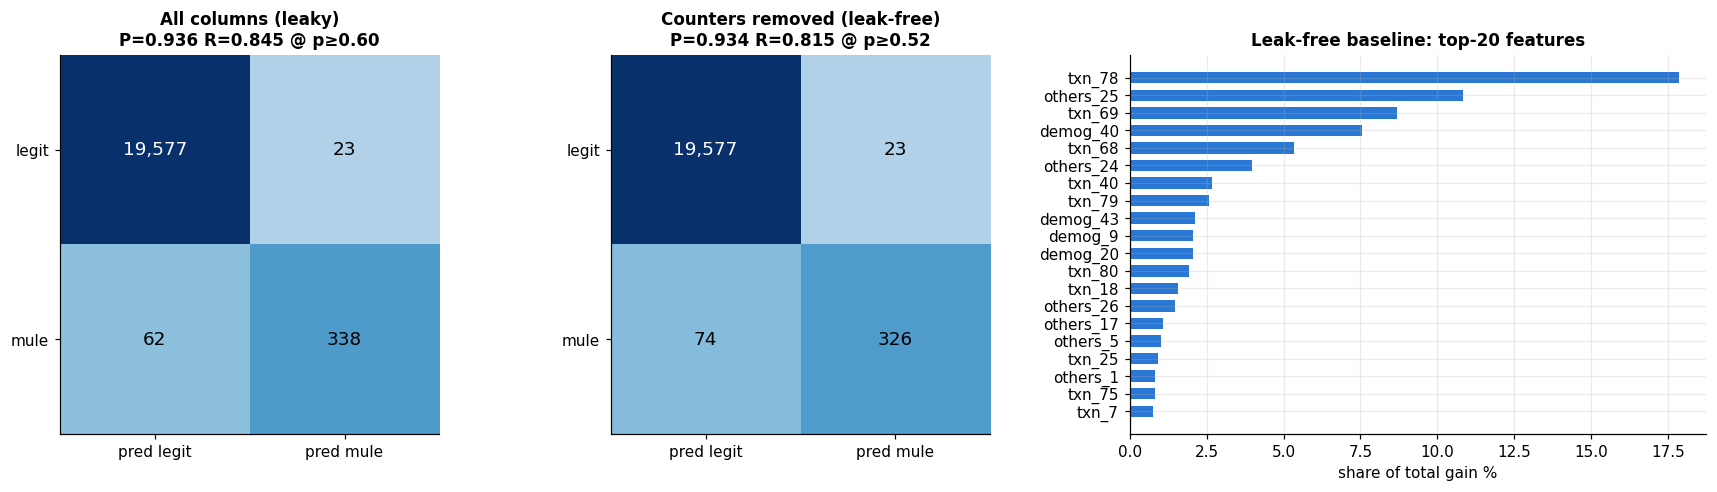

leak-free: top-5 features hold 50% of gain (was 90%)


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={'width_ratios': [1, 1, 1.3]})
for ax, (name, p_h, p_o) in zip(axes[:2], [('All columns (leaky)', p_cal, p_oof_cal), ('Counters removed (leak-free)', p_nl, p_nl_oof)]):
    pr_, rc_, th_ = precision_recall_curve(y_dev, p_o)
    t_ = th_[np.argmax((2 * pr_ * rc_ / (pr_ + rc_ + 1e-12))[:-1])]
    cm = confusion_matrix(y_hold, p_h >= t_)
    ax.imshow(cm, cmap='Blues', norm=plt.matplotlib.colors.LogNorm(vmin=1, vmax=len(y_hold))); ax.grid(False)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f'{v:,}', ha='center', va='center', fontsize=12, color='white' if v > 1000 else 'black')
    tn, fp, fn, tp = cm.ravel()
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['pred legit', 'pred mule'], yticklabels=['legit', 'mule'],
           title=f'{name}\nP={tp / (tp + fp):.3f} R={tp / (tp + fn):.3f} @ p≥{t_:.2f}')
imp_nl = base_nl.feature_importance('gain')
top = (imp_nl / imp_nl.sum() * 100).head(20)[::-1]
axes[2].barh(top.index, top.values, color=BLUE, height=.65)
axes[2].set(xlabel='share of total gain %', title='Leak-free baseline: top-20 features')
plt.tight_layout(); plt.show()
print(f'leak-free: top-5 features hold {imp_nl.head(5).sum() / imp_nl.sum():.0%} of gain (was {imp.head(5).sum() / imp.sum():.0%})')

## 8. Ablation — does the weighted loss help?
Same leak-free model with **no** class weight (`weight_power = 0`, weight = 49⁰ = 1). Its output is already on the
true-probability scale; it is compared with the weighted model after Platt calibration.

In [12]:
t = time()
unw = XGBCV(weight_power=0).fit(X_dev_nl, y_dev)
p_unw = unw.predict_proba(X_hold_nl)
print(f'trained in {time() - t:.0f}s | best iterations: {unw.best_iters_}')
platt_unw = LogisticRegression(C=1e6).fit(logit(unw.oof_)[:, None], y_dev)
abl = pd.DataFrame({f'weighted ×{w:.0f} + Platt': evaluate(y_hold, p_nl),
                    'unweighted (raw output)': evaluate(y_hold, p_unw),
                    'unweighted + Platt': evaluate(y_hold, platt_unw.predict_proba(logit(p_unw)[:, None])[:, 1])}).T
abl

trained in 10s | best iterations: [204, 285, 323, 169, 316]


,roc_auc,pr_auc,log_loss,brier
weighted ×49 + Platt,0.9932,0.9288,0.0164,0.0038
unweighted (raw output),0.9965,0.9516,0.0131,0.0033
unweighted + Platt,0.9965,0.9516,0.0133,0.0033


In [13]:
baseline_scores = pd.DataFrame({'raw baseline, all columns (leaky)': evaluate(y_hold, p_cal),
                                'leak-free baseline': evaluate(y_hold, p_nl)}).T
baseline_scores.to_csv('baseline_scores.csv')
baseline_scores

,roc_auc,pr_auc,log_loss,brier
"raw baseline, all columns (leaky)",0.9976,0.9602,0.0120,0.0030
leak-free baseline,0.9932,0.9288,0.0164,0.0038


## 9. Conclusions
| Finding | Evidence | Decision |
|---|---|---|
| **Raw baseline** (raw data, weighted ×49 + Platt) | holdout PR-AUC 0.960 · ROC-AUC 0.998 · log-loss 0.0120 | Reference only, because it is leaky (below). |
| **Calibration is required** after a weighted loss | raw weighted scores: log-loss 0.0195; prior correction 0.0173 (over-corrects: mean p 1.4% vs true 2.0%, since an early-stopped ensemble is not the exact weighted Bayes posterior the formula assumes); Platt 0.0120; isotonic 0.0119 but ties cost PR-AUC | **Platt scaling on OOF scores** from here on (keeps the ranking). |
| **The baseline is too good to be true** | 87% of the gain sits in two day-counter columns that stop when the bank freezes an account (EDA section 8) | **Drop the 9 counter columns.** They record the bank's reaction, not mule behaviour, and carry no signal on the open accounts a live system would score. |
| **Leak-free baseline = the bar to beat** | holdout **PR-AUC 0.929 · ROC-AUC 0.993 · log-loss 0.0164 · Brier 0.0038** (6× better log-loss than no-skill 0.098); 326/400 mules caught with 23 false alarms | All later notebooks use leak-free features. |
| The leak mostly sharpened probabilities | leaky vs leak-free at the F1 threshold: 338 vs 326 mules caught, same 23 false alarms | Losing the leak costs little in detection. |
| **×49 overfits fast** | validation weighted loss bottoms at ~100 rounds while train loss keeps falling; validation AUC still rising when early stopping fires: each mule counts as 49 rows, so trees memorise individual mules | Tune regularisation (notebook 04). |
| **Unweighted beats ×49** (leak-free) | PR-AUC 0.952 vs 0.929, log-loss 0.0131 vs 0.0164 | Keep the weight tied to the class ratio but **tune its strength**: weight = (#legit/#mule)^power, power ∈ [0, 1] (notebook 04). |